<a href="https://colab.research.google.com/github/xtianu/Docencia/blob/main/UPC/DAPR/S4.%20Flipped%20classroom/S4_FlippedClassroom_Exercises_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.m

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']


# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean

print(penguins[num_cols].isna().sum()) # shows me how many NaN there is per column

penguins_clean = penguins[['species'] + num_cols].dropna().copy() # the columns of the species and the one from befor and with .dropna remove the columns with NaN and .copy we make a copy of this list 

print(penguins_clean.isna().sum()) # Show us that our data are clean 
print(penguins_clean.shape)


# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
scaler = StandardScaler() # scaler = object that will perform the standardization 

penguins_scaled_df = pd.DataFrame(     #convert the array to panda dataframe/table
    scaler.fit_transform(penguins_clean[num_cols]), # .fit : calculates the mean and standard deviation for each feature, .transform : applies standardization formula to every value 
    columns=num_cols, # same name of columns 
    index=penguins_clean.index #same name of rows 
)

print(penguins_scaled_df.head())
print(penguins_scaled_df.mean().round(2))
print(penguins_scaled_df.std(ddof=0).round(2)) 
# penguin_scaled_df = normalized data frame 

# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)  #KMeans = class(nb of clusters, random position of initial clusters, nb of initialization of the clusters)

kmeans_labels = kmeans.fit_predict(penguins_scaled_df) # .fit_predict(): fits the K-means model to the data and then assigns each penguin to a cluster.

print(kmeans_labels[:10])

print(pd.Series(kmeans_labels).value_counts()) # pd.Series(kmeans_labels) converts the NumPy array of cluster labels into a pandas Series.   .value_counts() counts how many penguins are assigned to each cluster.



# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)

# 1. Add the cluster labels to our DataFrame
penguins_clean['kmeans_labels'] = kmeans_labels   # create a new column called kmeans_labels in our existing DataFrame.

# 2. Create a scatterplot
plt.figure(figsize=(8, 6))  # Creates a new figure, 8 inches wide and 6 inches tall.

sns.scatterplot(        # Calls the Seaborn function used to create a scatterplot.
    data=penguins_clean,   # DataFrame containing our data
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='kmeans_labels',   # Color each point according to its cluster, hue means that colors are determined by a variable.
    palette='deep'
)

plt.title('K-means clusters of penguins')
plt.show()

# 3. Create two pairplots

#First pairplot : real species 
sns.pairplot(
    data=penguins_clean,
    vars=num_cols,  # tells Seaborn to use the four numerical columns stored in our existing list num_cols.
    hue='species',
    diag_kind='hist'  # displays histograms (histogrammes) on the diagonal of the pairplot.
)

plt.show()

# Second pairplot : K-means clusters

sns.pairplot(
    data=penguins_clean,
    vars=num_cols,
    hue='kmeans_labels',
    diag_kind='hist'
)

plt.show()


# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'


# Convert species names into numeric labels
encoder = LabelEncoder()   # LabelEncoder to convert species names into numerical labels.
species_encoded = encoder.fit_transform(penguins_clean['species'])   # .fit() learns the different species names and assigns a number to each.   .transform() replaces each species name with its corresponding number.


# Compute the confusion matrix
cm = confusion_matrix(species_encoded, kmeans_labels)   # species_encoded: the real species labels.   kmeans_labels: the clusters predicted by K-means.


# Display it with readable names
cm_df = pd.DataFrame(
    cm,
    index=encoder.classes_,   # recover the species names that are still encoded there 
    columns=['Cluster 0', 'Cluster 1', 'Cluster 2']
)

print(cm_df)

ari = adjusted_rand_score(species_encoded, kmeans_labels)   # =1 if every clusters has one species 

print("Adjusted Rand Score:", ari)   

# f) YOUR CODE HERE (as a comment or markdown cell): interpretation

# Gentoo penguins are separated from the other species. Adelie and Chinstrap penguins are more difficult to distinguish because some of their characteristics overlap.
#Overall, K-means identifies meaningful groups, but the clusters do not correspond perfectly to the species.


# K-means using raw (non-normalized) data
kmeans_raw = KMeans(n_clusters=3, random_state=42, n_init=10)

raw_labels = kmeans_raw.fit_predict(penguins_clean[num_cols])

# Compare clustering quality
ari_raw = adjusted_rand_score(penguins_clean['species'], raw_labels)

print("ARI without normalization:", ari_raw)

# the Adjusted rand score is better the higher it is. It means that the clusters match the species. Here with normalization : ARI +- 0.8, without (raw) +- 0.3 
# which is way worse 


---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

In [ ]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()

print(np.isnan(X).any())  # equivalent to check missing values as what we used with panda in exo 1 

# b) YOUR CODE HERE: normalize X with StandardScaler

scaler = StandardScaler()  # Creates our standardization object, just like in Exercise 1.

X_scaled = scaler.fit_transform(X)   # .fit() calculates the mean and standard deviation for each of the two coordinates.      .transform() standardizes all six points using those values.

print(X_scaled.round(2))  # Displays our new standardized coordinates, rounded to 2 decimal places.


# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)

def euclidean_distance(p1, p2):        # define a function that receives two points, p1 and p2.
    squared_sum = 0                    # create a variable that will accumulate the sum of squared differences.

    for i in range(len(p1)):          # len(p1) returns the number of coordinates. Here, it's 2.   range(2) generates the indices 0 and 1.  The loop will therefore execute twice, once for each coordinate.
        difference = p1[i] - p2[i]    # calculate the difference between the corresponding coordinates.
        squared_sum += difference ** 2

    distance = squared_sum ** 0.5

    return distance                   # function returns the calculated distance.

# test it
print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))    # function in Numpy to calculate distance 

# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram

# Apply Agglomerative Clustering

clustering = AgglomerativeClustering(n_clusters=2).fit(X_scaled)  # AgglomerativeClustering(n_clusters=2) creates a model that will form two clusters.    .fit(X) applies the algorithm to the data and constructs the clustering hierarchy.

agglo_labels = clustering.labels_      # .labels_ retrieves the cluster assigned to each observation.

print(agglo_labels)


# Create a DataFrame with the original coordinates
#df1 = pd.DataFrame(X, columns=['x', 'y'])

# Add cluster labels
#df1['agglo'] = clustering.labels_

# Create the graphs
#fig = plt.figure(figsize=(10, 10))

#plt.subplot(211)
#sns.scatterplot(x='x', y='y', data=df1)

#plt.subplot(212)
#sns.scatterplot(x='x', y='y', hue='agglo', data=df1)

#plt.show()

# Dendrogram
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(8, 5))
dendrogram(Z)

plt.title('Hierarchical Clustering Dendrogram')
plt.ylabel('Ward linkage distance')
plt.show()





# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled
kmeans_result = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_scaled)  

print('Cluster labels {}'.format(kmeans_result.labels_))  # Gives the cluster assignment for each of our six observations, just like .labels_ in Agglomerative Clustering.
print('Cluster centroids {}'.format(kmeans_result.cluster_centers_))  # It gives the coordinates of the two centroids (centres des clusters) learned by K-means. (in standardized units)
print('Number of iterations required {}'.format(kmeans_result.n_iter_))  # Gives the number of iterations required for K-means to converge in the selected best run.

# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot
# Both have the same result for these exercice 
agglo_labels = clustering.labels_
kmeans_labels = kmeans_result.labels_
print(agglo_labels)
print(kmeans_labels)


# Compare Agglomerative and K-means clustering

plt.figure(figsize=(10, 4))

# First graph: Agglomerative Clustering
plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=agglo_labels)
plt.title('Agglomerative Clustering')
plt.xlabel('x')
plt.ylabel('y')

# Second graph: K-means
plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels)
plt.title('K-means Clustering')
plt.xlabel('x')
plt.ylabel('y')

plt.tight_layout()
plt.show()


# g) YOUR CODE HERE: cluster_sizes function using a dictionary

def cluster_sizes(labels):
    counts = {}

    for label in labels:  # We examine each cluster label, one after another.
        if label in counts:
            counts[label] = counts[label] + 1
        else:
            counts[label] = 1

    return counts

print(cluster_sizes(agglo_labels))
print(cluster_sizes(kmeans_labels))


---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

carat    0
depth    0
table    0
price    0
dtype: int64
carat    0
depth    0
table    0
price    0
dtype: int64


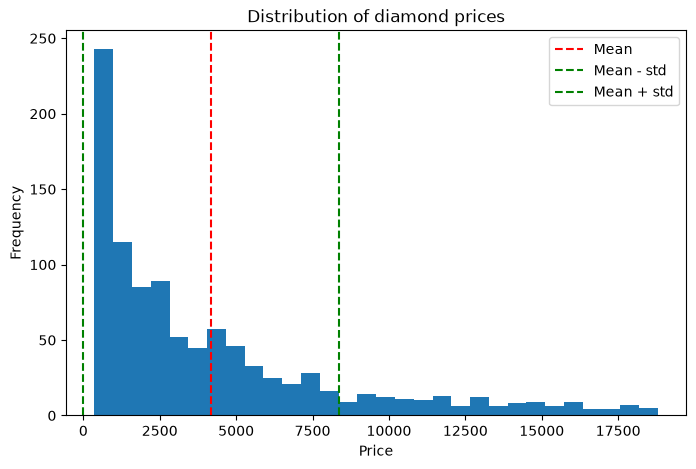

[-4.35207426e-17  3.46656037e-15 -1.66977543e-16 -5.32907052e-18]
[1. 1. 1. 1.]
[9270.10994236167, 7589.4138139142515, 7125.445565543292, 6977.0785380530215, 6953.387759928287, 7009.556884501499, 7054.190436032629, 7107.813808850151]


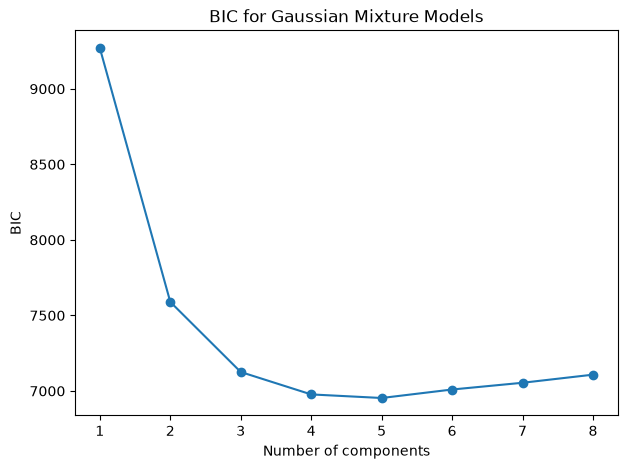

Optimal number of components: 5
[1 3 1 3 2 4 3 3 3 0 1 2 4 3 3 2 4 3 2 3 2 3 1 1 0 3 1 2 2 1 0 3 2 3 3 1 1
 3 3 2 3 3 1 2 0 1 2 2 2 2 1 2 0 2 0 0 0 1 0 3 0 1 2 2 1 1 3 3 3 0 0 1 0 2
 3 3 2 3 2 2 1 1 3 3 0 1 1 0 2 3 2 0 3 0 0 1 1 1 0 3 1 0 3 0 1 2 1 1 1 1 0
 1 3 3 0 0 2 0 0 3 0 2 2 2 1 3 1 1 1 0 1 0 1 1 1 1 1 0 3 4 2 0 1 4 0 1 0 2
 1 3 0 3 2 1 3 1 0 0 2 2 0 4 3 3 3 0 4 0 0 3 2 2 3 2 2 1 0 1 1 0 1 1 1 3 1
 3 0 3 1 1 4 0 1 2 2 0 1 2 2 0 1 0 1 3 1 0 3 0 1 0 1 2 2 0 1 3 3 0 4 3 0 1
 1 1 3 0 1 0 0 1 0 1 0 3 1 0 0 2 0 4 1 2 1 2 3 0 3 0 0 2 1 3 2 0 2 3 0 2 4
 2 1 1 4 0 0 1 3 2 2 2 1 0 3 4 0 3 3 1 0 1 0 0 2 1 1 1 4 3 2 2 1 1 2 0 0 0
 1 0 1 0 4 3 0 1 1 1 1 2 3 0 0 0 2 0 1 2 1 1 1 1 1 3 0 1 1 3 3 1 2 2 0 0 0
 2 0 0 2 0 0 3 2 2 0 2 1 1 1 2 3 0 0 1 3 2 1 1 0 2 1 0 2 3 1 0 0 2 0 0 1 0
 2 0 2 1 0 1 3 1 1 2 3 2 0 0 0 0 2 0 0 3 3 3 2 2 3 0 0 1 2 0 3 1 2 2 0 1 3
 3 2 2 1 1 0 0 0 0 2 1 0 1 0 1 0 0 3 3 2 3 0 1 0 2 1 3 0 1 1 0 2 0 1 2 1 3
 0 1 2 0 0 1 2 2 1 0 3 0 2 3 1 0 1 3 2 2 2 1 1 3 3 1 1 2 2 3 0 3 1 3

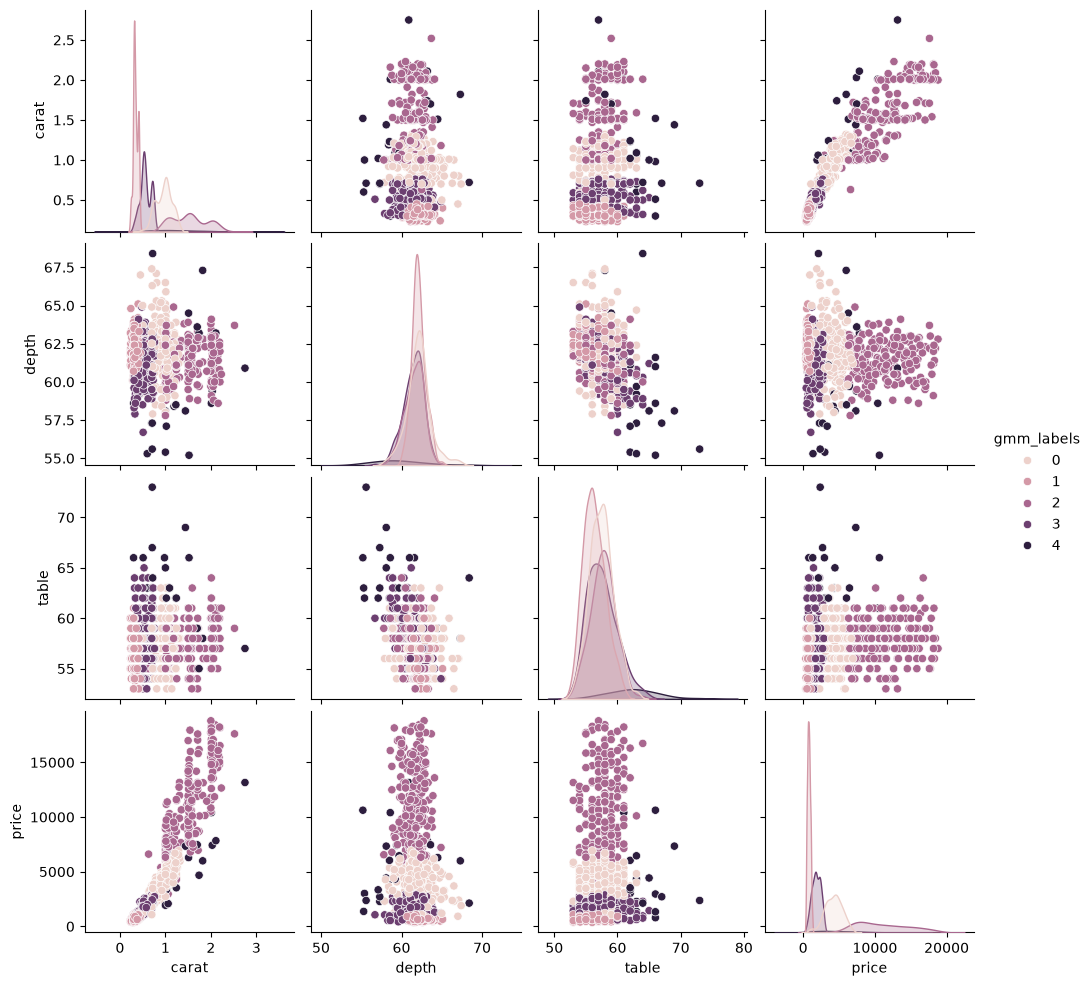

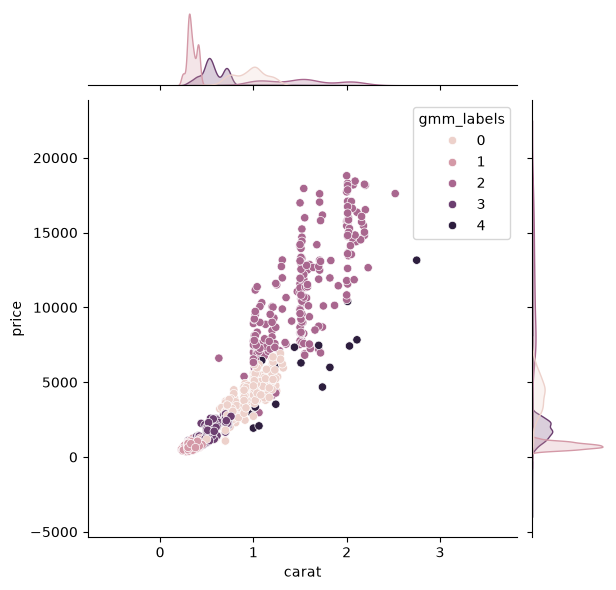

Optimal components with normalized data: 5
Optimal components with raw data: 5


In [3]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean

diamonds_num = diamonds[['carat', 'depth', 'table', 'price']]

print(diamonds_num.isna().sum())

diamonds_num = diamonds_num.dropna()

print(diamonds_num.isna().sum())


# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines

mean_price = diamonds_num['price'].mean()
std_price = diamonds_num['price'].std()

plt.figure(figsize=(8, 5))

plt.hist(diamonds_num['price'], bins=30)  #Creates a histogram with 30 intervals (classes).

plt.axvline(mean_price, color='red', linestyle='--', label='Mean')  #Draws a vertical line at a specified x-value.
plt.axvline(mean_price - std_price, color='green', linestyle='--', label='Mean - std')  # Draws a vertical line at a specified x-value.
plt.axvline(mean_price + std_price, color='green', linestyle='--', label='Mean + std')  # Draws a vertical line at a specified x-value.

plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Distribution of diamond prices')
plt.legend()
plt.show()

# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler

scaler = StandardScaler()

diamonds_scaled = scaler.fit_transform(diamonds_num)

print(diamonds_scaled.mean(axis=0))
print(diamonds_scaled.std(axis=0))


# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components

bic = []    # will contain the BIC scores of our eight models.
n_components_range = range(1, 9)

for n in n_components_range:
    gmm = mixture.GaussianMixture(n_components=n, covariance_type='full') #n_components=n: number of Gaussian components in the model. This changes at every iteration.   covariance_type='full': each Gaussian component can have its own covariance matrix, allowing tilted and elongated distributions.  random_state=0: makes the random initialization reproducible
    gmm.fit(diamonds_scaled)  #train the GMM on our normalized diamond data. Model estimates the means, covariances and weights of its Gaussian components.
    bic.append(gmm.bic(diamonds_scaled))  #gmm.bic(diamonds_scaled) calculates the BIC of the fitted model.     bic.append(...) adds that BIC value to our list.

print(bic)

# BIC vs numbers of components 

plt.figure(figsize=(7, 5))

plt.plot(n_components_range, bic, marker='o')

plt.xlabel('Number of components')
plt.ylabel('BIC')
plt.title('BIC for Gaussian Mixture Models')
plt.xticks(n_components_range)

plt.show()

# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM

# best number of composent (4) 

best_n = n_components_range[np.argmin(bic)]
#np.argmin(bic) finds the index (indice) of the smallest value in the BIC list.
#Our smallest BIC is at index 3, because Python starts counting at 0.
#n_components_range[3] returns 4, because our range starts at 1.
#best_n therefore stores the value 4.

print("Optimal number of components:", best_n)


gmm = mixture.GaussianMixture(n_components=best_n, covariance_type='full', random_state=0)

gmm_labels = gmm.fit_predict(diamonds_scaled)

print(gmm_labels)

# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)

diamonds_num['gmm_labels'] = gmm_labels

sns.pairplot(diamonds_num,   # sns.pairplot : This is a Seaborn function that creates several graphs to compare relationships between numerical variables.Dataframe to use : diamonds_num
             vars=['carat', 'depth', 'table', 'price'],
             hue='gmm_labels')  # hue means that observations are colored according to their cluster.c

plt.show()

sns.jointplot(data=diamonds_num, x='carat', y='price', hue='gmm_labels')

plt.show()

# g) YOUR CODE HERE (as a comment or markdown cell): interpretation

# The 4 components selected by BIC seem reasonable. The pairplot shows different groups of diamonds, mainly distinguished by carat and price. However, some clusters overlap, so the separation is not perfect.

# By looking at the plots, I might have guessed 2 or 3 main groups based on diamond size and price. It is difficult to identify exactly 4 groups visually, which shows why BIC is useful for model selection.


diamonds_raw = diamonds_num[['carat', 'depth', 'table', 'price']]

bic_raw = []

for n in n_components_range:
    gmm_raw = mixture.GaussianMixture(n_components=n, covariance_type='full', random_state=0)
    gmm_raw.fit(diamonds_raw)
    bic_raw.append(gmm_raw.bic(diamonds_raw))

best_n_raw = n_components_range[np.argmin(bic_raw)]

print("Optimal components with normalized data:", best_n)
print("Optimal components with raw data:", best_n_raw)

# It would have been 5 with raw data so not the same 
